In [2]:
import os, json, time, pickle, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
DATA_DIR    = os.path.join(OUT, 'data')
SCALER_DIR  = os.path.join(OUT, 'scalers')
PLOT_DIR    = os.path.join(OUT, 'plots')
MODEL_DIR   = os.path.join(OUT, 'models')
RESULTS_DIR = os.path.join(OUT, 'results')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

INPUT_WINDOW = 48
HORIZON      = 24
BATCH_SIZE   = 16
HIDDEN_DIM   = 32
GRU_LAYERS   = 1
ATTN_HEADS   = 4
DROPOUT      = 0.2
SEEDS        = [42, 7, 123, 2024, 999]

print(f"Device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"GPU   : {torch.cuda.get_device_name(0)}")

Device: cuda
GPU   : NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
X_train  = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
Y_train  = np.load(os.path.join(DATA_DIR, 'Y_train.npy'))
At_train = np.load(os.path.join(DATA_DIR, 'At_train.npy'))
X_val    = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
Y_val    = np.load(os.path.join(DATA_DIR, 'Y_val.npy'))
At_val   = np.load(os.path.join(DATA_DIR, 'At_val.npy'))
X_test   = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
Y_test   = np.load(os.path.join(DATA_DIR, 'Y_test.npy'))
At_test  = np.load(os.path.join(DATA_DIR, 'At_test.npy'))

with open(os.path.join(SCALER_DIR, 'pm25_scaler.pkl'), 'rb') as f:
    pm25_scaler = pickle.load(f)
with open(os.path.join(SCALER_DIR, 'feature_scaler.pkl'), 'rb') as f:
    feat_scaler = pickle.load(f)

N = X_train.shape[2]
F = X_train.shape[3]

print(f"Train {X_train.shape[0]:,} | Val {X_val.shape[0]:,} | Test {X_test.shape[0]:,} samples")
print(f"N={N} stations, F={F} features")

Train 13,873 | Val 2,917 | Test 2,918 samples
N=37 stations, F=14 features


In [4]:
inv_pm = lambda a: pm25_scaler.inverse_transform(a.reshape(-1,1)).reshape(a.shape)
Yr_train, Yr_val, Yr_test = inv_pm(Y_train), inv_pm(Y_val), inv_pm(Y_test)

log_scaler = StandardScaler().fit(np.log1p(np.clip(Yr_train, 0, None)).reshape(-1,1))

def to_log(a):
    return log_scaler.transform(
        np.log1p(np.clip(a, 0, None)).reshape(-1,1)).reshape(a.shape).astype(np.float32)

def from_log(a):
    lg = log_scaler.inverse_transform(a.reshape(-1,1)).reshape(a.shape)
    return np.expm1(lg)

Yl_train, Yl_val, Yl_test = to_log(Yr_train), to_log(Yr_val), to_log(Yr_test)

fm, fs = feat_scaler.mean_[0], feat_scaler.scale_[0]
def anchor_from_X(X):
    return to_log(X[:, -1, :, 0] * fs + fm)

Anc_train, Anc_val, Anc_test = anchor_from_X(X_train), anchor_from_X(X_val), anchor_from_X(X_test)

print(f"Raw skew  : {pd.Series(Yr_train.flatten()).skew():.2f}")
print(f"Log skew  : {pd.Series(Yl_train.flatten()).skew():.2f}")
print(f"Roundtrip : {from_log(Yl_train[:1,:1,:1])[0,0,0]:.2f} vs actual {Yr_train[0,0,0]:.2f}")

Raw skew  : 2.58
Log skew  : -0.18
Roundtrip : 143.75 vs actual 143.75


In [5]:
_df = pd.read_csv(os.path.join(V2_DIR, 'EcoTwin_Final_Dataset.csv'),
                  parse_dates=['Timestamp'], usecols=['Timestamp'])
timestamps = np.array(sorted(_df['Timestamp'].unique()))
T = len(timestamps)

train_end_idx, val_end_idx = int(T*0.70), int(T*0.85)
TRAIN_END = pd.Timestamp(timestamps[train_end_idx-1])
VAL_END   = pd.Timestamp(timestamps[val_end_idx-1])

masks = {
    'train': timestamps <= TRAIN_END,
    'val'  : (timestamps > TRAIN_END) & (timestamps <= VAL_END),
    'test' : timestamps > VAL_END,
}

def future_time_windows(ts_subset):
    ts = pd.DatetimeIndex(ts_subset)
    tf = np.stack([ts.hour, ts.dayofweek, ts.month,
                   (ts.dayofweek >= 5).astype(int)], axis=1).astype(np.float32)
    n = len(ts) - (INPUT_WINDOW + HORIZON) + 1
    out = np.zeros((n, HORIZON, 4), dtype=np.float32)
    for i in range(n):
        out[i] = tf[i+INPUT_WINDOW : i+INPUT_WINDOW+HORIZON]
    return out

TF = {k: future_time_windows(timestamps[m]) for k, m in masks.items()}

tm, ts_ = feat_scaler.mean_[10:14], feat_scaler.scale_[10:14]
for k in TF:
    TF[k] = ((TF[k] - tm) / ts_).astype(np.float32)

assert TF['train'].shape[0] == X_train.shape[0], "sample count mismatch"
assert TF['val'].shape[0]   == X_val.shape[0]
assert TF['test'].shape[0]  == X_test.shape[0]
print(f"Future time — train {TF['train'].shape} | val {TF['val'].shape} | test {TF['test'].shape}")
print("Aligned with windows.")

Future time — train (13873, 24, 4) | val (2917, 24, 4) | test (2918, 24, 4)
Aligned with windows.


In [6]:
class EcoDataset(Dataset):
    def __init__(self, X, Y, At, TFut, Anc):
        self.X, self.Y, self.At, self.TF, self.A = X, Y, At, TFut, Anc
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return (torch.from_numpy(self.X[i]).float(),
                torch.from_numpy(self.At[i]).float(),
                torch.from_numpy(self.TF[i]).float(),
                torch.from_numpy(self.A[i]).float(),
                torch.from_numpy(self.Y[i]).float())

tr_ds = EcoDataset(X_train, Yl_train, At_train, TF['train'], Anc_train)
va_ds = EcoDataset(X_val,   Yl_val,   At_val,   TF['val'],   Anc_val)
te_ds = EcoDataset(X_test,  Yl_test,  At_test,  TF['test'],  Anc_test)

tr_ld = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
va_ld = DataLoader(va_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
te_ld = DataLoader(te_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Batches — train {len(tr_ld)} | val {len(va_ld)} | test {len(te_ld)}")

Batches — train 868 | val 183 | test 183


In [7]:
class WATGCN(nn.Module):
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2, n_time_feats=4):
        super().__init__()
        self.input_proj = nn.Linear(in_features, hidden_dim)
        self.gcn_linear = nn.Linear(hidden_dim, hidden_dim)
        self.gcn_norm   = nn.LayerNorm(hidden_dim)
        self.act        = nn.ReLU()
        self.gru        = nn.GRU(hidden_dim, hidden_dim, gru_layers, batch_first=True,
                                 dropout=dropout if gru_layers > 1 else 0)
        self.attention  = nn.MultiheadAttention(hidden_dim, attn_heads,
                                                dropout=dropout, batch_first=True)
        self.attn_norm  = nn.LayerNorm(hidden_dim)
        self.dropout    = nn.Dropout(dropout)

        self.time_enc = nn.Sequential(
            nn.Linear(n_time_feats, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim))

        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim*2, hidden_dim), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 1))

        self.anchor_gate = nn.Parameter(torch.linspace(1.0, 0.3, forecast_horizon))

        self.H, self.FH = hidden_dim, forecast_horizon

    def forward(self, X, At, TFut, Anchor):
        B, T, N, _ = X.shape

        H = self.act(self.input_proj(X))

        I = torch.eye(N, device=At.device).unsqueeze(0).unsqueeze(0)
        A = At + I
        A = A / A.sum(dim=-1, keepdim=True).clamp(min=1e-6)

        Hg = self.act(self.gcn_norm(self.gcn_linear(torch.matmul(A, H)))) + H

        Hf = Hg.permute(0,2,1,3).reshape(B*N, T, self.H)
        g, _ = self.gru(Hf)
        g = self.dropout(g)
        a, _ = self.attention(g, g, g)
        ctx = self.attn_norm(a + g)[:, -1, :]

        t_emb = self.time_enc(TFut).unsqueeze(1).expand(B, N, self.FH, self.H)
        t_emb = t_emb.reshape(B*N, self.FH, self.H)
        ctx_r = ctx.unsqueeze(1).expand(-1, self.FH, -1)

        resid = self.decoder(torch.cat([ctx_r, t_emb], dim=-1)).squeeze(-1)
        resid = resid.reshape(B, N, self.FH).permute(0,2,1)

        anchor = Anchor.unsqueeze(1) * self.anchor_gate.view(1, self.FH, 1)
        return resid + anchor


_m = WATGCN(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS, HORIZON, N, DROPOUT)
print(f"Parameters: {sum(p.numel() for p in _m.parameters()):,}")
del _m

Parameters: 15,577


In [8]:
def train_model(seed=42, max_epochs=60, patience=12, lr=1e-3, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)

    model = WATGCN(F, HIDDEN_DIM, GRU_LAYERS, ATTN_HEADS,
                   HORIZON, N, DROPOUT).to(DEVICE)
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, 'min', factor=0.5, patience=5)
    crit  = nn.HuberLoss(delta=1.0)

    best_val, best_state, ctr = float('inf'), None, 0
    hist = {'train': [], 'val': []}

    if verbose:
        print(f"  {'Ep':>3} | {'Train':>8} | {'Val':>8} | {'LR':>7} | {'Time':>6} | Status")
        print("  " + "-"*56)

    for ep in range(1, max_epochs+1):
        t0 = time.time()
        model.train(); tr = 0.0
        for Xb, Ab, Tb, Anb, Yb in tr_ld:
            Xb, Ab, Tb = Xb.to(DEVICE), Ab.to(DEVICE), Tb.to(DEVICE)
            Anb, Yb    = Anb.to(DEVICE), Yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(Xb, Ab, Tb, Anb), Yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tr += loss.item() * Xb.size(0)
        tr /= len(tr_ds)

        model.eval(); vl = 0.0
        with torch.no_grad():
            for Xb, Ab, Tb, Anb, Yb in va_ld:
                Xb, Ab, Tb = Xb.to(DEVICE), Ab.to(DEVICE), Tb.to(DEVICE)
                Anb, Yb    = Anb.to(DEVICE), Yb.to(DEVICE)
                vl += crit(model(Xb, Ab, Tb, Anb), Yb).item() * Xb.size(0)
        vl /= len(va_ds)

        sched.step(vl)
        hist['train'].append(tr); hist['val'].append(vl)

        if vl < best_val - 1e-5:
            best_val, best_state, ctr = vl, copy.deepcopy(model.state_dict()), 0
            tag = 'best'
        else:
            ctr += 1
            tag = f'{ctr}/{patience}'

        if verbose:
            print(f"  {ep:>3} | {tr:>8.5f} | {vl:>8.5f} | "
                  f"{opt.param_groups[0]['lr']:>7.1e} | {time.time()-t0:>5.1f}s | {tag}")

        if ctr >= patience:
            if verbose:
                print(f"  Early stop at epoch {ep}")
            break

    model.load_state_dict(best_state)
    return model, best_val, hist


def predict(model):
    model.eval()
    P, A_ = [], []
    with torch.no_grad():
        for Xb, Ab, Tb, Anb, Yb in te_ld:
            P.append(model(Xb.to(DEVICE), Ab.to(DEVICE),
                           Tb.to(DEVICE), Anb.to(DEVICE)).cpu().numpy())
            A_.append(Yb.numpy())
    return np.concatenate(P), np.concatenate(A_)


def evaluate(pred_log, actual_log, label=''):
    pr, ar = from_log(pred_log), from_log(actual_log)
    rmse = np.sqrt(mean_squared_error(ar.flatten(), pr.flatten()))
    mae  = mean_absolute_error(ar.flatten(), pr.flatten())
    r2   = r2_score(ar.flatten(), pr.flatten())
    if label:
        print(f"{label} — RMSE {rmse:.2f} | MAE {mae:.2f} | R2 {r2:.4f}")
    return {'rmse': rmse, 'mae': mae, 'r2': r2, 'preds': pr, 'actual': ar}

print("Functions ready.")

Functions ready.


In [9]:
model_0, val_0, hist_0 = train_model(seed=42)
p0, a0 = predict(model_0)
res_single = evaluate(p0, a0, 'Single model')

print("\nRMSE by horizon:")
for h in [0, 5, 11, 17, 23]:
    r = np.sqrt(mean_squared_error(res_single['actual'][:,h,:].flatten(),
                                   res_single['preds'][:,h,:].flatten()))
    print(f"  +{h+1:>2}h : {r:.2f}")

   Ep |    Train |      Val |      LR |   Time | Status
  --------------------------------------------------------
    1 |  0.17244 |  0.14107 | 1.0e-03 |  26.7s | best
    2 |  0.14747 |  0.13771 | 1.0e-03 |  16.8s | best
    3 |  0.14106 |  0.13760 | 1.0e-03 |  15.6s | best
    4 |  0.13799 |  0.13668 | 1.0e-03 |  15.5s | best
    5 |  0.13444 |  0.14166 | 1.0e-03 |  15.5s | 1/12
    6 |  0.13209 |  0.13983 | 1.0e-03 |  15.4s | 2/12
    7 |  0.12983 |  0.15096 | 1.0e-03 |  15.5s | 3/12
    8 |  0.12794 |  0.14104 | 1.0e-03 |  15.4s | 4/12
    9 |  0.12513 |  0.14168 | 1.0e-03 |  15.9s | 5/12
   10 |  0.12321 |  0.15546 | 5.0e-04 |  15.6s | 6/12
   11 |  0.11969 |  0.14878 | 5.0e-04 |  15.6s | 7/12
   12 |  0.11865 |  0.15043 | 5.0e-04 |  15.5s | 8/12
   13 |  0.11775 |  0.14636 | 5.0e-04 |  15.7s | 9/12
   14 |  0.11705 |  0.15071 | 5.0e-04 |  16.2s | 10/12
   15 |  0.11608 |  0.15432 | 5.0e-04 |  15.9s | 11/12
   16 |  0.11523 |  0.15681 | 2.5e-04 |  15.5s | 12/12
  Early stop at ep

In [12]:
models, preds_list = [], []

for s in SEEDS:
    print(f"\n--- seed {s} ---")
    m, v, _ = train_model(seed=s, verbose=True)
    p, a = predict(m)
    models.append(m); preds_list.append(p)
    r = evaluate(p, a)
    print(f"  val {v:.5f} | RMSE {r['rmse']:.2f} | R2 {r['r2']:.4f}")

ens_log = np.mean(preds_list, axis=0)
res_ens = evaluate(ens_log, a, '\nENSEMBLE')

print("\nRMSE by horizon:")
for h in [0, 5, 11, 17, 23]:
    r = np.sqrt(mean_squared_error(res_ens['actual'][:,h,:].flatten(),
                                   res_ens['preds'][:,h,:].flatten()))
    print(f"  +{h+1:>2}h : {r:.2f}")


--- seed 42 ---
   Ep |    Train |      Val |      LR |   Time | Status
  --------------------------------------------------------
    1 |  0.17244 |  0.14107 | 1.0e-03 |  16.8s | best
    2 |  0.14747 |  0.13771 | 1.0e-03 |  16.9s | best
    3 |  0.14106 |  0.13760 | 1.0e-03 |  16.4s | best
    4 |  0.13799 |  0.13668 | 1.0e-03 |  16.7s | best
    5 |  0.13444 |  0.14166 | 1.0e-03 |  15.6s | 1/12
    6 |  0.13209 |  0.13983 | 1.0e-03 |  15.6s | 2/12
    7 |  0.12983 |  0.15096 | 1.0e-03 |  15.5s | 3/12
    8 |  0.12794 |  0.14104 | 1.0e-03 |  15.6s | 4/12
    9 |  0.12513 |  0.14168 | 1.0e-03 |  15.5s | 5/12
   10 |  0.12321 |  0.15546 | 5.0e-04 |  15.5s | 6/12
   11 |  0.11969 |  0.14878 | 5.0e-04 |  15.5s | 7/12
   12 |  0.11865 |  0.15043 | 5.0e-04 |  15.5s | 8/12
   13 |  0.11775 |  0.14636 | 5.0e-04 |  15.5s | 9/12
   14 |  0.11705 |  0.15071 | 5.0e-04 |  15.6s | 10/12
   15 |  0.11608 |  0.15432 | 5.0e-04 |  15.5s | 11/12
   16 |  0.11523 |  0.15681 | 2.5e-04 |  15.5s | 12/12
 

In [13]:
pr, ar = res_ens['preds'], res_ens['actual']
swing = ar.max(axis=1) - ar.min(axis=1)
q33, q66 = np.percentile(swing, [33, 66])

groups = {
    'Stable  ': swing <= q33,
    'Moderate': (swing > q33) & (swing <= q66),
    'Volatile': swing > q66,
}

sq_err = ((ar - pr)**2).transpose(0,2,1)
total_sq = sq_err.sum()

print(f"{'Regime':<10} {'Samples':>9} {'RMSE':>8} {'MAE':>8} {'% of error':>12}")
print("-"*52)
for lbl, msk in groups.items():
    a_ = ar.transpose(0,2,1)[msk]
    p_ = pr.transpose(0,2,1)[msk]
    print(f"{lbl:<10} {msk.sum():>9,} {np.sqrt(((a_-p_)**2).mean()):>8.2f} "
          f"{np.abs(a_-p_).mean():>8.2f} {sq_err[msk].sum()/total_sq*100:>11.1f}%")

print(f"\nOverall RMSE: {res_ens['rmse']:.2f}")

Regime       Samples     RMSE      MAE   % of error
----------------------------------------------------
Stable        35,637    28.11    21.10         6.3%
Moderate      35,620    44.78    33.55        15.9%
Volatile      36,709    97.76    69.03        77.9%

Overall RMSE: 64.59


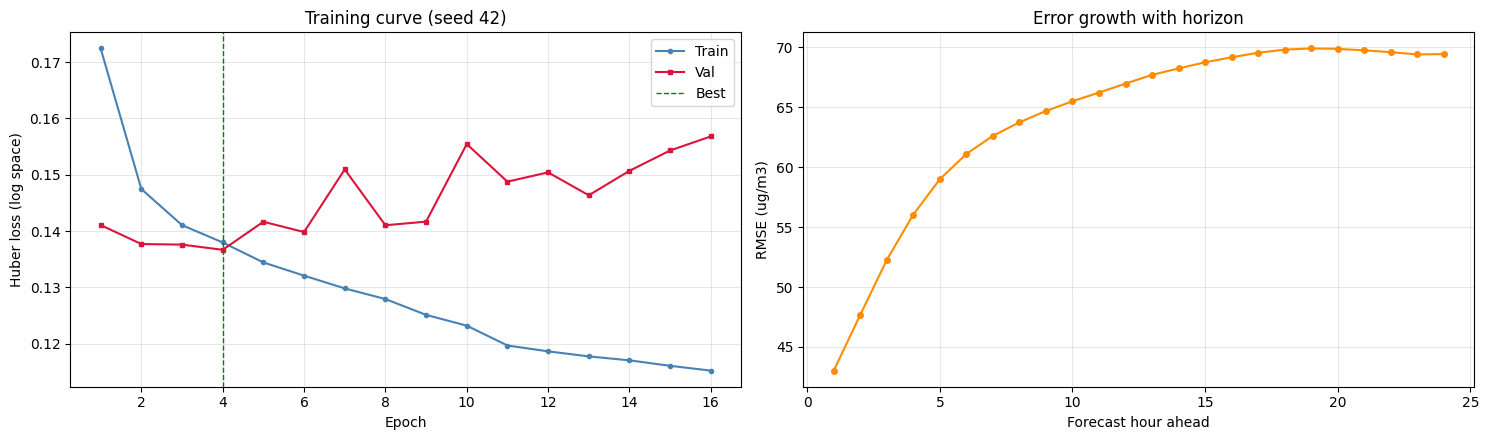

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# loss curve
axes[0].plot(range(1, len(hist_0['train'])+1), hist_0['train'],
             marker='o', ms=3, label='Train', color='steelblue')
axes[0].plot(range(1, len(hist_0['val'])+1), hist_0['val'],
             marker='s', ms=3, label='Val', color='crimson')
axes[0].axvline(int(np.argmin(hist_0['val']))+1, color='green', ls='--', lw=1, label='Best')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Huber loss (log space)')
axes[0].set_title('Training curve (seed 42)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# rmse by horizon
h_rmse = [np.sqrt(mean_squared_error(ar[:,h,:].flatten(), pr[:,h,:].flatten()))
          for h in range(HORIZON)]
axes[1].plot(range(1, HORIZON+1), h_rmse, marker='o', ms=4, color='darkorange')
axes[1].set_xlabel('Forecast hour ahead'); axes[1].set_ylabel('RMSE (ug/m3)')
axes[1].set_title('Error growth with horizon')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'final_model_summary.png'), dpi=150, bbox_inches='tight')
plt.show()

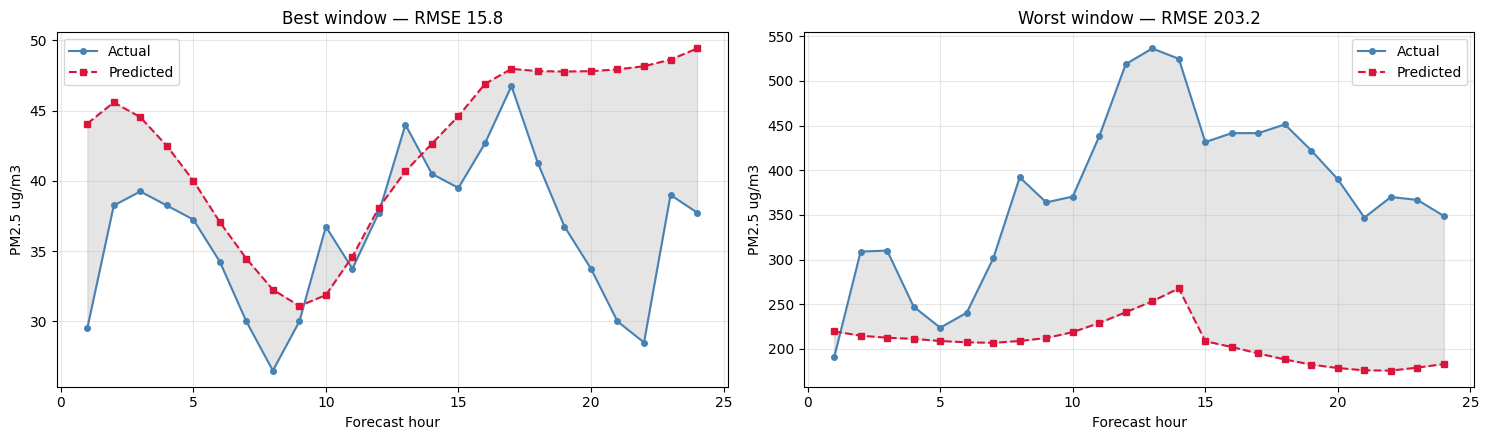

In [15]:
win_rmse = np.sqrt(((ar - pr)**2).mean(axis=(1,2)))
best_i, worst_i = int(np.argmin(win_rmse)), int(np.argmax(win_rmse))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (lbl, i) in zip(axes, [('Best window', best_i), ('Worst window', worst_i)]):
    ax.plot(range(1,25), ar[i,:,0], marker='o', ms=4, color='steelblue', label='Actual')
    ax.plot(range(1,25), pr[i,:,0], marker='s', ms=4, color='crimson', ls='--', label='Predicted')
    ax.fill_between(range(1,25), ar[i,:,0], pr[i,:,0], color='gray', alpha=0.2)
    ax.set_title(f'{lbl} — RMSE {win_rmse[i]:.1f}')
    ax.set_xlabel('Forecast hour'); ax.set_ylabel('PM2.5 ug/m3')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, 'final_best_worst.png'), dpi=150, bbox_inches='tight')
plt.show()

In [16]:
df_st = pd.read_excel(os.path.join(V2_DIR, 'Delhi_list_v2.xlsx'))
df_st.columns = df_st.columns.str.strip().str.lower()
names = df_st['station'].str.strip().tolist()

rows = []
for n in range(N):
    a_, p_ = ar[:,:,n].flatten(), pr[:,:,n].flatten()
    rows.append({'Station': names[n] if n < len(names) else f'S{n}',
                 'RMSE': round(np.sqrt(mean_squared_error(a_, p_)), 2),
                 'MAE' : round(mean_absolute_error(a_, p_), 2),
                 'R2'  : round(r2_score(a_, p_), 4)})

per_st = pd.DataFrame(rows).sort_values('RMSE')
print(per_st.to_string(index=False))
per_st.to_csv(os.path.join(RESULTS_DIR, 'final_per_station.csv'), index=False)

                           Station  RMSE   MAE     R2
                  IGI Airport (T3) 40.09 28.48 0.5516
                        Lodhi Road 40.38 27.75 0.6137
                         Aya Nagar 41.07 28.38 0.5205
                Sri Aurobindo Marg 44.50 29.49 0.6066
                         Pusa IITM 47.76 32.82 0.6248
Major Dhyan Chand National Stadium 48.07 33.19 0.6689
                         Najafgarh 49.76 31.64 0.4458
                          Shadipur 51.43 34.59 0.4788
                         Pusa DPCC 52.25 36.76 0.6119
                 CRRI Mathura Road 53.42 36.20 0.5398
                            Alipur 54.30 38.71 0.5461
          Jawaharlal Nehru Stadium 55.34 37.36 0.6391
                       NSIT Dwarka 56.84 34.37 0.2541
                       Mandir Marg 57.53 40.72 0.4568
    Dr. Karni Singh Shooting Range 58.29 38.26 0.6214
                     Chandni Chowk 60.80 40.46 0.6321
                   Dwarka-Sector 8 61.58 40.94 0.6073
                          Si

In [17]:
for i, m in enumerate(models):
    torch.save(m.state_dict(), os.path.join(MODEL_DIR, f'watgcn_final_seed{SEEDS[i]}.pt'))

config = {
    'in_features': F, 'hidden_dim': HIDDEN_DIM, 'gru_layers': GRU_LAYERS,
    'attn_heads': ATTN_HEADS, 'forecast_horizon': HORIZON, 'n_stations': N,
    'dropout': DROPOUT, 'input_window': INPUT_WINDOW,
    'log_target': True, 'seeds': SEEDS,
}
with open(os.path.join(MODEL_DIR, 'final_config.json'), 'w') as f:
    json.dump(config, f, indent=2)

with open(os.path.join(SCALER_DIR, 'log_scaler.pkl'), 'wb') as f:
    pickle.dump(log_scaler, f)

metrics = {
    'model': 'WA-TGCN ensemble (5 seeds)',
    'rmse': round(res_ens['rmse'], 2),
    'mae' : round(res_ens['mae'], 2),
    'r2'  : round(res_ens['r2'], 4),
    'rmse_by_horizon': {f'+{h+1}h': round(h_rmse[h], 2) for h in range(HORIZON)},
    'rmse_by_regime': {
        lbl.strip(): round(float(np.sqrt(((ar.transpose(0,2,1)[msk] -
                                           pr.transpose(0,2,1)[msk])**2).mean())), 2)
        for lbl, msk in groups.items()
    },
}
with open(os.path.join(RESULTS_DIR, 'final_metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)

print(f"Saved {len(models)} models, config, log scaler, metrics.")
print(f"\nFinal — RMSE {res_ens['rmse']:.2f} | MAE {res_ens['mae']:.2f} | R2 {res_ens['r2']:.4f}")

Saved 5 models, config, log scaler, metrics.

Final — RMSE 64.59 | MAE 41.50 | R2 0.5887
